# Customer Churn Model Prediction

## Phase 0: Enviroment setup

In [50]:
# Install and Import Libraries
# -- Safe Installations --
"""    
import sys
import subprocess

packages = [
    'pandas',
    'numpy',
    'seaborn',
    'matplotlib',
    'scikit-learn',
    'xgboost',
    'imbalanced-learn',
    'openpyxl'
]
for package in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', package, '--quiet'])

print('All packages installed')

"""

# -- Core Data Libraries --
import pandas as pd
import numpy as np

# -- Visualization Libraries --
import matplotlib.pyplot as plt
import seaborn as sns

# -- Machine Learning --
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE


# -- Display Settings --
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 5)

print('All Libraries loaded successfully!')
print(f'Pandas version: {pd.__version__}')
print(f'Numpy version : {np.__version__}')


All Libraries loaded successfully!
Pandas version: 3.1.1
Numpy version : 2.5.4


In [51]:

# -- Core Data Libraries --
import pandas as pd
import numpy as np

# -- Visualization Libraries --
import matplotlib.pyplot as plt
import seaborn as sns

# -- Machine Learning --
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE


# -- Display Settings --
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 5)

##  Phase 1: Data loading

In [52]:
# Loading the dataset
df = pd.read_excel(r'~/Documents/Data Science/ML OPs/Churn_project/Churn_Project_Dataset.xlsx')
print('Datase loaded Successfully!')
print(f'Dataset Loaded Shape: {df.shape}')
print(f'       > {df.shape[0]} customers(rows)')
print(f'       > {df.shape[1]} features(columns)')


Datase loaded Successfully!
Dataset Loaded Shape: (7043, 21)
       > 7043 customers(rows)
       > 21 features(columns)


In [53]:
# View the first 10 columns 
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [54]:
# Data Inspection 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [55]:
# CHcke for NULL or missing values 
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [56]:
# Investigate the missing values in the dataframe specifically on the column with missing values.
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [57]:
# Handle missing values for TotalCharges using Tenure x Monthly Charges
df['TotalCharges'] = df['TotalCharges'].fillna(df['tenure'] * df['MonthlyCharges'])

In [58]:
# verify that filling na worked.
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [59]:
# We view the filled missing values

dff = df[df['tenure'] == 0]
dff

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,0.00,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,0.00,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,0.00,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,0.00,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,0.00,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,0.00,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,0.00,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,0.00,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,0.00,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,0.00,No


In [60]:
# Convert SeniorCitizens from 0/1 to NO/Yes

df['SeniorCitizen'] = df['SeniorCitizen'].map({0 : 'No', 1 : 'Yes'})

# Verify
print(f'SeniorCitizen unique values: {df['SeniorCitizen'].unique()}')


SeniorCitizen unique values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [61]:
# Display unique values per column
cat_cols = df.select_dtypes(include=['object', 'str']).columns.tolist()

for col in cat_cols:
    print(f'{col:20s}    -> {df[col].unique().tolist()}')
    print()


customerID              -> ['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU', '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU', '9763-GRSKD', '7469-LKBCI', '8091-TTVAX', '0280-XJGEX', '5129-JLPIS', '3655-SNQYZ', '8191-XWSZG', '9959-WOFKT', '4190-MFLUW', '4183-MYFRB', '8779-QRDMV', '1680-VDCWW', '1066-JKSGK', '3638-WEABW', '6322-HRPFA', '6865-JZNKO', '6467-CHFZW', '8665-UTDHZ', '5248-YGIJN', '8773-HHUOZ', '3841-NFECX', '4929-XIHVW', '6827-IEAUQ', '7310-EGVHZ', '3413-BMNZE', '6234-RAAPL', '6047-YHPVI', '6572-ADKRS', '5380-WJKOV', '8168-UQWWF', '8865-TNMNX', '9489-DEDVP', '9867-JCZSP', '4671-VJLCL', '4080-IIARD', '3714-NTNFO', '5948-UJZLF', '7760-OYPDY', '7639-LIAYI', '2954-PIBKO', '8012-SOUDQ', '9420-LOJKX', '6575-SUVOI', '7495-OOKFY', '4667-QONEA', '1658-BYGOY', '8769-KKTPH', '5067-XJQFU', '3957-SQXML', '5954-BDFSG', '0434-CSFON', '1215-FIGMP', '0526-SXDJP', '0557-ASKVU', '5698-BQJOH', '5122-CYFXA', '8627-ZYGSZ', '3410-YOQBQ', '3170-NMYVV', '7410-

Contract                -> ['Month-to-month', 'One year', 'Two year']

PaperlessBilling        -> ['Yes', 'No']

PaymentMethod           -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']

Churn                   -> ['No', 'Yes']



In [62]:
#--Drop unncessary column and encoder categoricals
#--Step 1: Drop customerID, since its just an identifier

df = df.drop(columns = ['customerID'])

#--Step 2: Columns where 'No Internet Service' = 'NO'
# These columns basically have no internet, ist not a different category

no_internet_cols = ['OnlineSecurity',
                    'OnlineBackup',
                    'DeviceProtection',
                    'TechSupport',
                    'StreamingTV',
                    'StreamingMovies',
                    'MultipleLines'
                    ]

for col in no_internet_cols:
    df[col] = df[col].replace({'No internet service' : 'No', 
                               'No phone service' : 'No'
                               })

#--Step 3: Binary columns -> map Yes=1, No=0

binary_cols = ['gender',
               'SeniorCitizen',
               'Partner',
               'Dependents',
               'PhoneService',
               'MultipleLines',
               'OnlineSecurity',
               'OnlineBackup',
               'DeviceProtection',
               'TechSupport',
               'StreamingTV',
               'StreamingMovies',
               'PaperlessBilling'
               ]

binary_map = {'Yes' : 1, 
              'No' : 0, 
              'Male' : 1, 
              'Female' : 0
              }

for col in binary_cols:
    df[col] = df[col].map(binary_map)


#--Step : 4 One-hot encoding for multi-category columns

df = pd.get_dummies(df,
                    columns = [
                        'InternetService',
                        'Contract',
                        'PaymentMethod'],
                        drop_first = False)

#--Step 5: Encode target column (Churn)

df['Churn'] = df['Churn'].map({'Yes' : 1, 'No' : 0})


# Verify
print(f'Econding complete! New Shape: {df.shape}')
print(f'\nChurn value counts:\n {df['Churn'].value_counts()}')
print(f'\n Sample of new columns: {df.columns.tolist}')



Econding complete! New Shape: (7043, 27)

Churn value counts:
 Churn
0    5174
1    1869
Name: count, dtype: int64

 Sample of new columns: <bound method IndexOpsMixin.tolist of Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='str')>


In [63]:
df.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,True,False,False,False,True,False,False,False,False,True
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,True,False,False,False,True,False,True,False,False,False
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,False,True,False,True,False,False,False,False,True,False
5,0,0,0,0,8,1,1,0,0,1,0,1,1,1,99.65,820.50,1,False,True,False,True,False,False,False,False,True,False
6,1,0,0,1,22,1,1,0,1,0,0,1,0,1,89.10,1949.40,0,False,True,False,True,False,False,False,True,False,False
7,0,0,0,0,10,0,0,1,0,0,0,0,0,0,29.75,301.90,0,True,False,False,True,False,False,False,False,False,True
8,0,0,1,0,28,1,1,0,0,1,1,1,1,1,104.80,3046.05,1,False,True,False,True,False,False,False,False,True,False
9,1,0,0,1,62,1,0,1,1,0,0,0,0,0,56.15,3487.95,0,True,False,False,False,True,False,True,False,False,False


In [64]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
gender,7043.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00
SeniorCitizen,7043.00,0.16,0.37,0.00,0.00,0.00,0.00,1.00
Partner,7043.00,0.48,0.50,0.00,0.00,0.00,1.00,1.00
Dependents,7043.00,0.30,0.46,0.00,0.00,0.00,1.00,1.00
tenure,7043.00,32.37,24.56,0.00,9.00,29.00,55.00,72.00
PhoneService,7043.00,0.90,0.30,0.00,1.00,1.00,1.00,1.00
MultipleLines,7043.00,0.42,0.49,0.00,0.00,0.00,1.00,1.00
OnlineSecurity,7043.00,0.29,0.45,0.00,0.00,0.00,1.00,1.00
OnlineBackup,7043.00,0.34,0.48,0.00,0.00,0.00,1.00,1.00
DeviceProtection,7043.00,0.34,0.48,0.00,0.00,0.00,1.00,1.00


## Phase 3 -- Exploratory Data Analysis
### Univariate Analysis
### Bivariate Analysis
### Multivariate Analysis

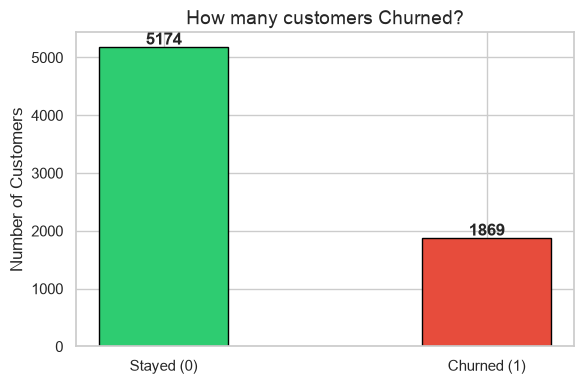

Stayed: 5,174 (73.5)%
Stayed: 1,869 (26.5)%


In [65]:
#--univariate analysis
#--Churn distribution
#--How many customers stayed and how many left?

churn_counts = df['Churn'].value_counts()

plt.figure(figsize = (6, 4))
plt.bar(['Stayed (0)', 'Churned (1)'],
        churn_counts.values,
        color = ['#2ecc71', '#e74c3c'],
        edgecolor = 'black',
        width = 0.4)

#--Add the numbers on top of the bar

for i, v in enumerate(churn_counts.values):
    plt.text(i, v+50, str(v), ha = 'center', fontweight = 'bold')

plt.title('How many customers Churned?', fontsize = 14)
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


print(f'Stayed: {churn_counts[0]:,} ({churn_counts[0]/len(df)*100 :.1f})%')
print(f'Stayed: {churn_counts[1]:,} ({churn_counts[1]/len(df)*100 :.1f})%')

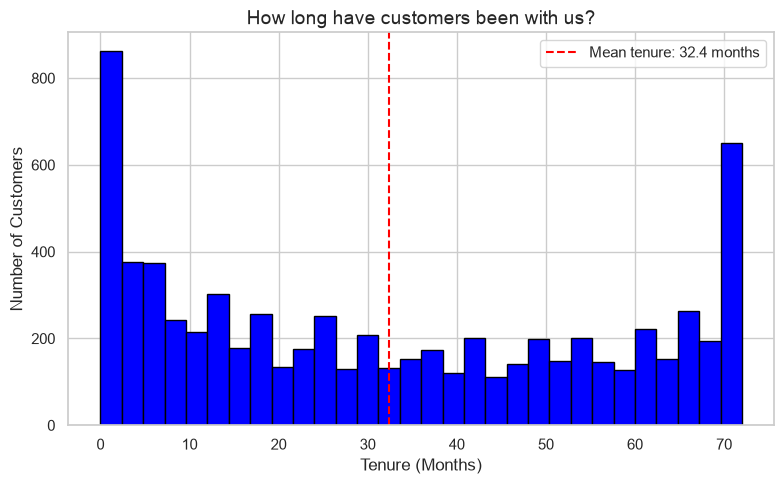

Shorterst tenure: 0 months
Average tenure: 32.4 months
Longest tenure: 72 months


In [66]:
# How long have Customers stayed with us?
# Distribution of Tenure


plt.figure(figsize=(8, 5))
plt.hist(df['tenure'], bins=30, color='blue', edgecolor='black', alpha= 1.0)
plt.axvline(df['tenure'].mean(), color='red', linestyle='--', label= f'Mean tenure: {df['tenure'].mean():.1f} months')
plt.title('How long have customers been with us?', fontsize=14)
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()


print(f'Shorterst tenure: {df['tenure'].min()} months')
print(f'Average tenure: {df['tenure'].mean():.1f} months')
print(f'Longest tenure: {df['tenure'].max()} months')

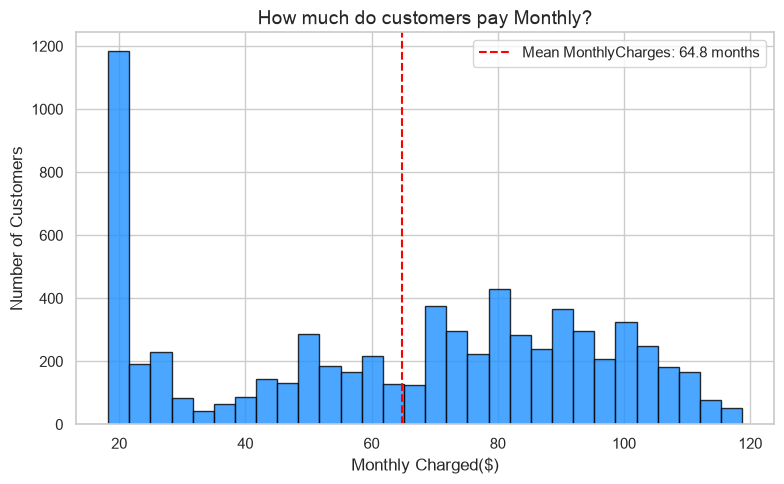

Lowest Charge: 18.25
Average Charge: 64.76
Maximum Charge: 118.75


In [67]:
# how much do customers pay monthly
# Distribution of MonthlyCharges

plt.figure(figsize=(8, 5))
plt.hist(df['MonthlyCharges'], bins=30, color='dodgerblue', edgecolor='black', alpha= 0.8)
plt.axvline(df['MonthlyCharges'].mean(), color='red', linestyle='--', label= f'Mean MonthlyCharges: {df['MonthlyCharges'].mean():.1f} months')
plt.title('How much do customers pay Monthly?', fontsize=14)
plt.xlabel('Monthly Charged($)')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()


print(f'Lowest Charge: {df['MonthlyCharges'].min()}')
print(f'Average Charge: {df['MonthlyCharges'].mean():.2f}')
print(f'Maximum Charge: {df['MonthlyCharges'].max()}')

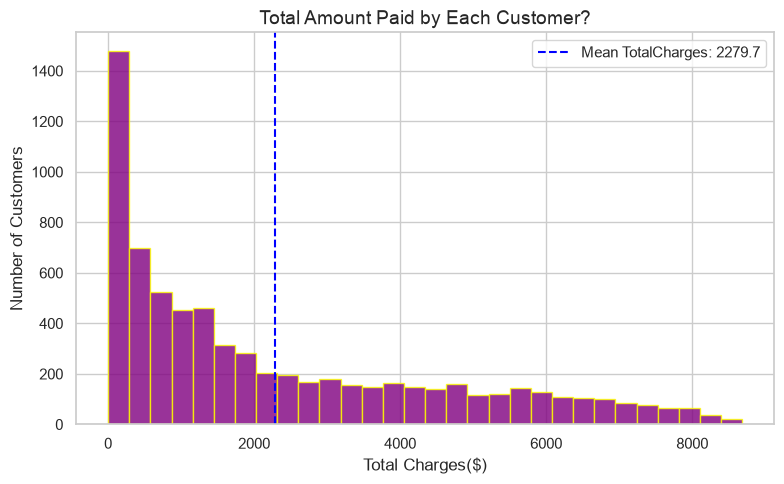

Lowest Total: 0.0
Average Total: 2279.73
Highest Total: 8684.8


In [68]:
#  Total Amount Paid by Each Customer
# Distribution of TotalCharges




plt.figure(figsize=(8, 5))
plt.hist(df['TotalCharges'], bins=30, color='purple', edgecolor='yellow', alpha= 0.8)
plt.axvline(df['TotalCharges'].mean(), color='blue', linestyle='--', label= f'Mean TotalCharges: {df['TotalCharges'].mean():.1f}')
plt.title('Total Amount Paid by Each Customer?', fontsize=14)
plt.xlabel('Total Charges($)')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()


print(f'Lowest Total: {df['TotalCharges'].min()}')
print(f'Average Total: {df['TotalCharges'].mean():.2f}')
print(f'Highest Total: {df['TotalCharges'].max()}')

<Figure size 800x500 with 0 Axes>

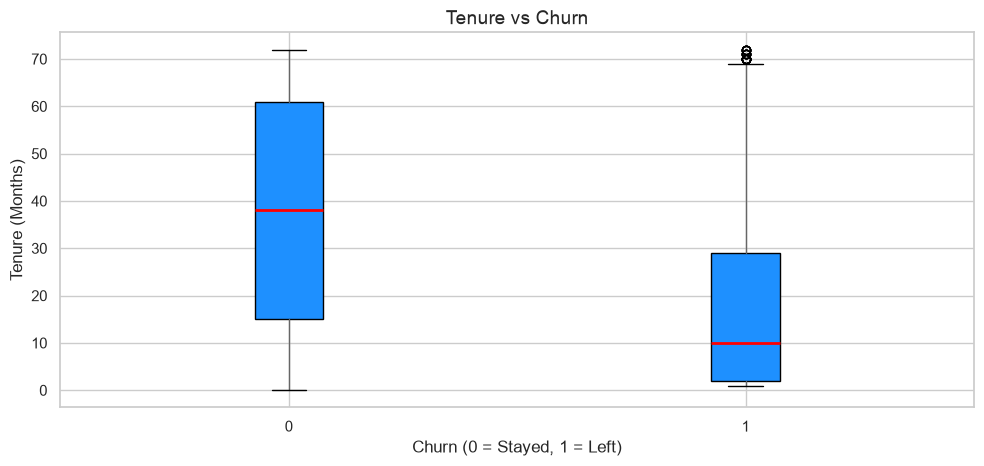

Average Tenure by Churn Status:
Churn
0   37.57
1   17.98
Name: tenure, dtype: float64


In [69]:
# Tenure vs Churn
# How do churners stay before they leave?
# Are new customers the ones churning the most?

plt.figure(figsize=(8, 5))
df.boxplot(column='tenure', by='Churn', patch_artist=True, 
           boxprops=dict(facecolor='dodgerblue', 
                         color='black'),
           medianprops=dict(color='red', 
                            linewidth= 2))
plt.title('Tenure vs Churn', fontsize=14)
plt.suptitle('')
plt.xlabel('Churn (0 = Stayed, 1 = Left)')
plt.ylabel('Tenure (Months)')
plt.tight_layout()
plt.show()


print(f'Average Tenure by Churn Status:')
print(df.groupby('Churn')['tenure'].mean().round(2))


<Figure size 800x500 with 0 Axes>

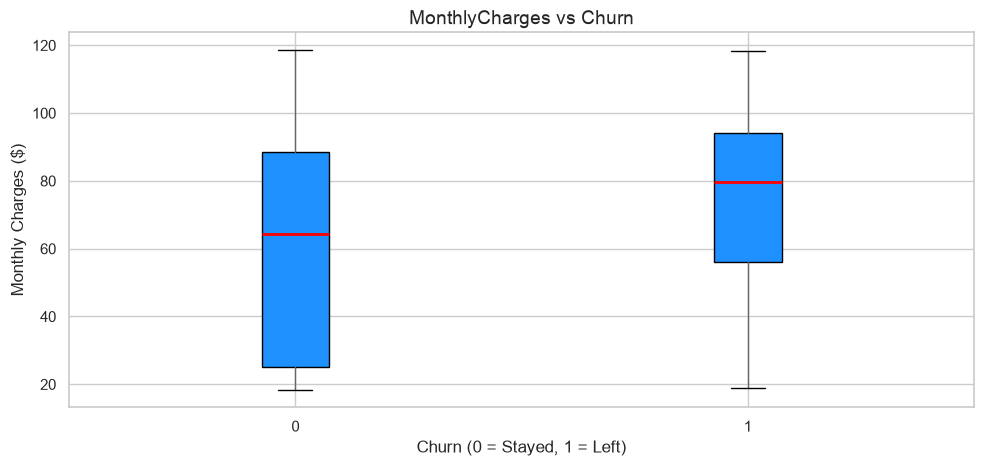

Average MonthlyCharges by Churn Status:
Churn
0   61.27
1   74.44
Name: MonthlyCharges, dtype: float64


In [70]:
# Monthly Charges vs Churn
# Do customers who pay more churn more?


plt.figure(figsize=(8, 5))
df.boxplot(column='MonthlyCharges', by='Churn', patch_artist=True, 
           boxprops=dict(facecolor='dodgerblue', 
                         color='black'),
           medianprops=dict(color='red', 
                            linewidth= 2))
plt.title('MonthlyCharges vs Churn', fontsize=14)
plt.suptitle('')
plt.xlabel('Churn (0 = Stayed, 1 = Left)')
plt.ylabel('Monthly Charges ($)')
plt.tight_layout()
plt.show()


print(f'Average MonthlyCharges by Churn Status:')
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

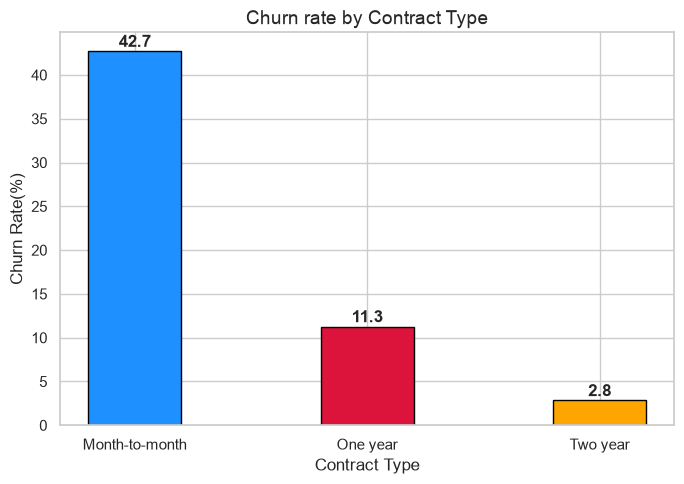

In [71]:
# Does the type of contract affect churn?
# Calculate churn rate by contract_type

contract_churn = df.groupby(['Contract_Month-to-month', 'Contract_One year', 'Contract_Two year'])['Churn'].mean() * 100

df['Contract_Type'] = 'Month-to-month'
df.loc[df['Contract_One year'] == 1, 'Contract_Type'] = 'One year'
df.loc[df['Contract_Two year'] == 1, 'Contract_Type'] = 'Two year' 


Churn_by_contract = df.groupby('Contract_Type')['Churn'].mean() * 100

# Draw a bar chart of the churn rate for each contract type

plt.figure(figsize=(7, 5))
bars = plt.bar(Churn_by_contract.index, Churn_by_contract.values, color = ['dodgerblue', 'crimson', 'orange'],
               edgecolor = 'black', width=0.4)

# Add percentages labels on bars
for bar, val in zip(bars, Churn_by_contract.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             f'{val:.1f}', ha = 'center', fontweight = 'bold')

plt.title('Churn rate by Contract Type', fontsize=14)
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate(%)')
plt.tight_layout()
plt.show()

### Feedback: "Contract Type Vs Churn"

### Absolutely! Shorter contract tenure means zero commitment, hence, its easy to leave.

In [72]:
df.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_Type
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,True,False,False,True,False,False,False,False,True,False,Month-to-month
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,True,False,False,False,True,False,False,False,False,True,One year
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,Month-to-month
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,True,False,False,False,True,False,True,False,False,False,One year
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,False,True,False,True,False,False,False,False,True,False,Month-to-month
5,0,0,0,0,8,1,1,0,0,1,0,1,1,1,99.65,820.50,1,False,True,False,True,False,False,False,False,True,False,Month-to-month
6,1,0,0,1,22,1,1,0,1,0,0,1,0,1,89.10,1949.40,0,False,True,False,True,False,False,False,True,False,False,Month-to-month
7,0,0,0,0,10,0,0,1,0,0,0,0,0,0,29.75,301.90,0,True,False,False,True,False,False,False,False,False,True,Month-to-month
8,0,0,1,0,28,1,1,0,0,1,1,1,1,1,104.80,3046.05,1,False,True,False,True,False,False,False,False,True,False,Month-to-month
9,1,0,0,1,62,1,0,1,1,0,0,0,0,0,56.15,3487.95,0,True,False,False,False,True,False,True,False,False,False,One year


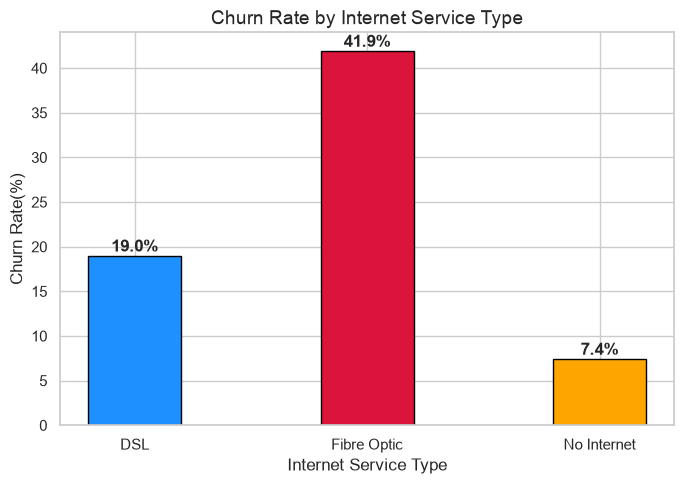

Churn Rate by Internet Service
Internet_Type
DSL           19.00
Fibre Optic   41.90
No Internet    7.40
Name: Churn, dtype: float64


In [73]:
# Internet Service vs Churn
# 'Does the Type of Internet Service affect churn?'
# Rebuild Internet Service column for plotting

df['Internet_Type'] = 'No Internet'
df.loc[df['InternetService_DSL'] == 1, 'Internet_Type'] = 'DSL'
df.loc[df['InternetService_Fiber optic'] == 1, 'Internet_Type'] = 'Fibre Optic'

churn_by_internet = df.groupby('Internet_Type')['Churn'].mean() * 100

plt.figure(figsize=(7, 5))
bars = plt.bar(churn_by_internet.index, churn_by_internet.values, color = ['dodgerblue', 'crimson', 'orange'],
               edgecolor='black', width=0.4)

# Add percentage labels on bars
for bar, val in zip(bars, churn_by_internet.values):
    plt.text(bar.get_x() + bar.get_width()/2, 
             bar.get_height() + 0.5, 
             f'{val:.1f}%', 
             ha = 'center', 
             fontweight = 'bold')

plt.title('Churn Rate by Internet Service Type', fontsize=14)
plt.xlabel('Internet Service Type')
plt.ylabel('Churn Rate(%)')
plt.tight_layout()
plt.show()

print(f'Churn Rate by Internet Service')
print(churn_by_internet.round(1))

### Feedback: Internet Service Vs Churn

### Yes! Fiber optic is a strong indicator for churn.

In [74]:
df['Internet_Type'] = 'No Internet'

PaymentMethod_Type
Bank transfer(Auto)   16.71
Credit card (auto)    15.24
Electronic check      45.29
Mailed check          19.11
Name: Churn, dtype: float64


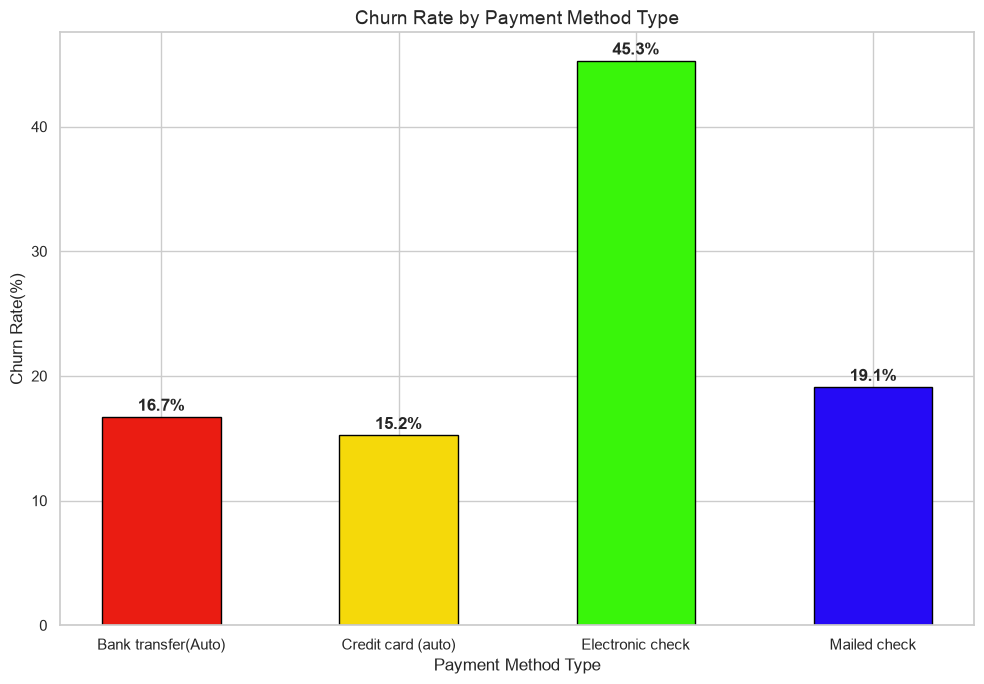

Churn Rate by Payment Method Type
PaymentMethod_Type
Bank transfer(Auto)   16.70
Credit card (auto)    15.20
Electronic check      45.30
Mailed check          19.10
Name: Churn, dtype: float64


In [75]:
df['PaymentMethod_Type'] = 'Bank transfer(Auto)'
df.loc[df['PaymentMethod_Credit card (automatic)'] == 1, 'PaymentMethod_Type'] = 'Credit card (auto)'
df.loc[df['PaymentMethod_Electronic check'] == 1, 'PaymentMethod_Type'] = 'Electronic check'
df.loc[df['PaymentMethod_Mailed check'] == 1, 'PaymentMethod_Type'] = 'Mailed check'

churn_by_payment = df.groupby('PaymentMethod_Type')['Churn'].mean()* 100
print(f'{churn_by_payment}')

plt.figure(figsize=(10,7))
bars = plt.bar(churn_by_payment.index, churn_by_payment.values, color = ["#ea1c12", "#f5d90a", "#39f50a", "#250af5"], edgecolor = 'black', width = 0.5)

# Add percentage level on bars

for bar, val in zip(bars, churn_by_payment.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:.1f}%', ha = 'center', fontweight = 'bold')



plt.title('Churn Rate by Payment Method Type', fontsize=14)
plt.xlabel('Payment Method Type')
plt.ylabel('Churn Rate(%)')
plt.tight_layout()
plt.show()

print(f'Churn Rate by Payment Method Type')
print(churn_by_payment.round(1))

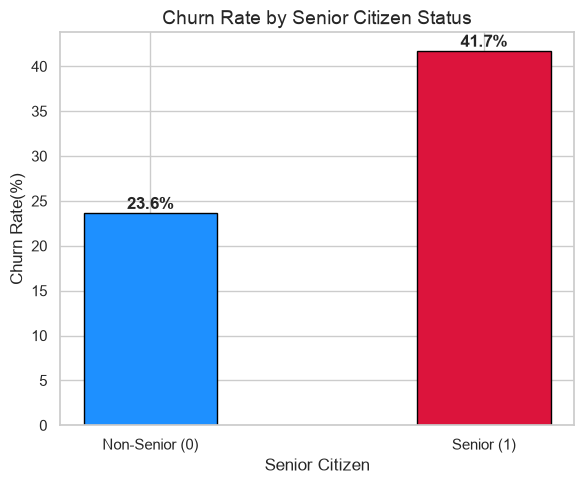

Churn Rate by Senior Citizen Status
SeniorCitizen
0   23.60
1   41.70
Name: Churn, dtype: float64

Customer count by SeniorCitizen Status:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


In [76]:
## SeniorCitizen vs Churn
## Do SeniorCitizens Churn more than non-senior citizen'

churn_by_senior = df.groupby('SeniorCitizen')['Churn'].mean() * 100


plt.figure(figsize=(6, 5))
bars = plt.bar(['Non-Senior (0)', 'Senior (1)'], churn_by_senior.values, color = ['dodgerblue', 'crimson'], edgecolor = 'black', width = 0.4)

# Add percentage labels on bars
for bar, val in zip(bars, churn_by_senior.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:.1f}%', ha='center', fontweight = 'bold')



plt.title('Churn Rate by Senior Citizen Status', fontsize = 14)
plt.xlabel('Senior Citizen')
plt.ylabel('Churn Rate(%)')
plt.tight_layout()
plt.show()


print('Churn Rate by Senior Citizen Status')
print(churn_by_senior.round(1))
print('\nCustomer count by SeniorCitizen Status:')
print(df['SeniorCitizen'].value_counts())

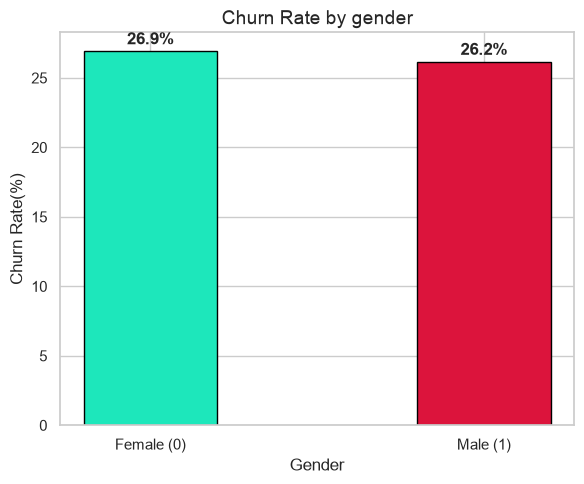

Churn Rate by gender
gender
0   26.90
1   26.20
Name: Churn, dtype: float64


In [77]:
## Gender vs Churn
## Does Gender affects whether customer churns or not?

churn_by_gender = df.groupby('gender')['Churn'].mean() * 100


plt.figure(figsize=(6, 5))
bars = plt.bar(['Female (0)', 'Male (1)'], churn_by_gender.values, color = ["#1DE7BB", 'crimson'], edgecolor = 'black', width = 0.4)

# Add percentage labels on bars
for bar, val in zip(bars, churn_by_gender.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:.1f}%', ha='center', fontweight = 'bold')



plt.title('Churn Rate by gender', fontsize = 14)
plt.xlabel('Gender')
plt.ylabel('Churn Rate(%)')
plt.tight_layout()
plt.show()


print('Churn Rate by gender')
print(churn_by_gender.round(1))


## Feedback: Gender Vs Chrun

### Virtually no difference at all. 0.7% separates females from males. Gender is not a useful indicator of churn.
### Bivariate Analysis Summary:

#### Contract Type (Very strong indicator for churn)

#### Fibre Optic(Internet Service) - (Very strong indicator for churn)

#### Tenure (Very strong indicator for churn)

#### Senior Citizen (Useful indicator for churn)

#### Monthly Charges (Useful indicator for churn)

#### Gender (Not an important indicator for churn)


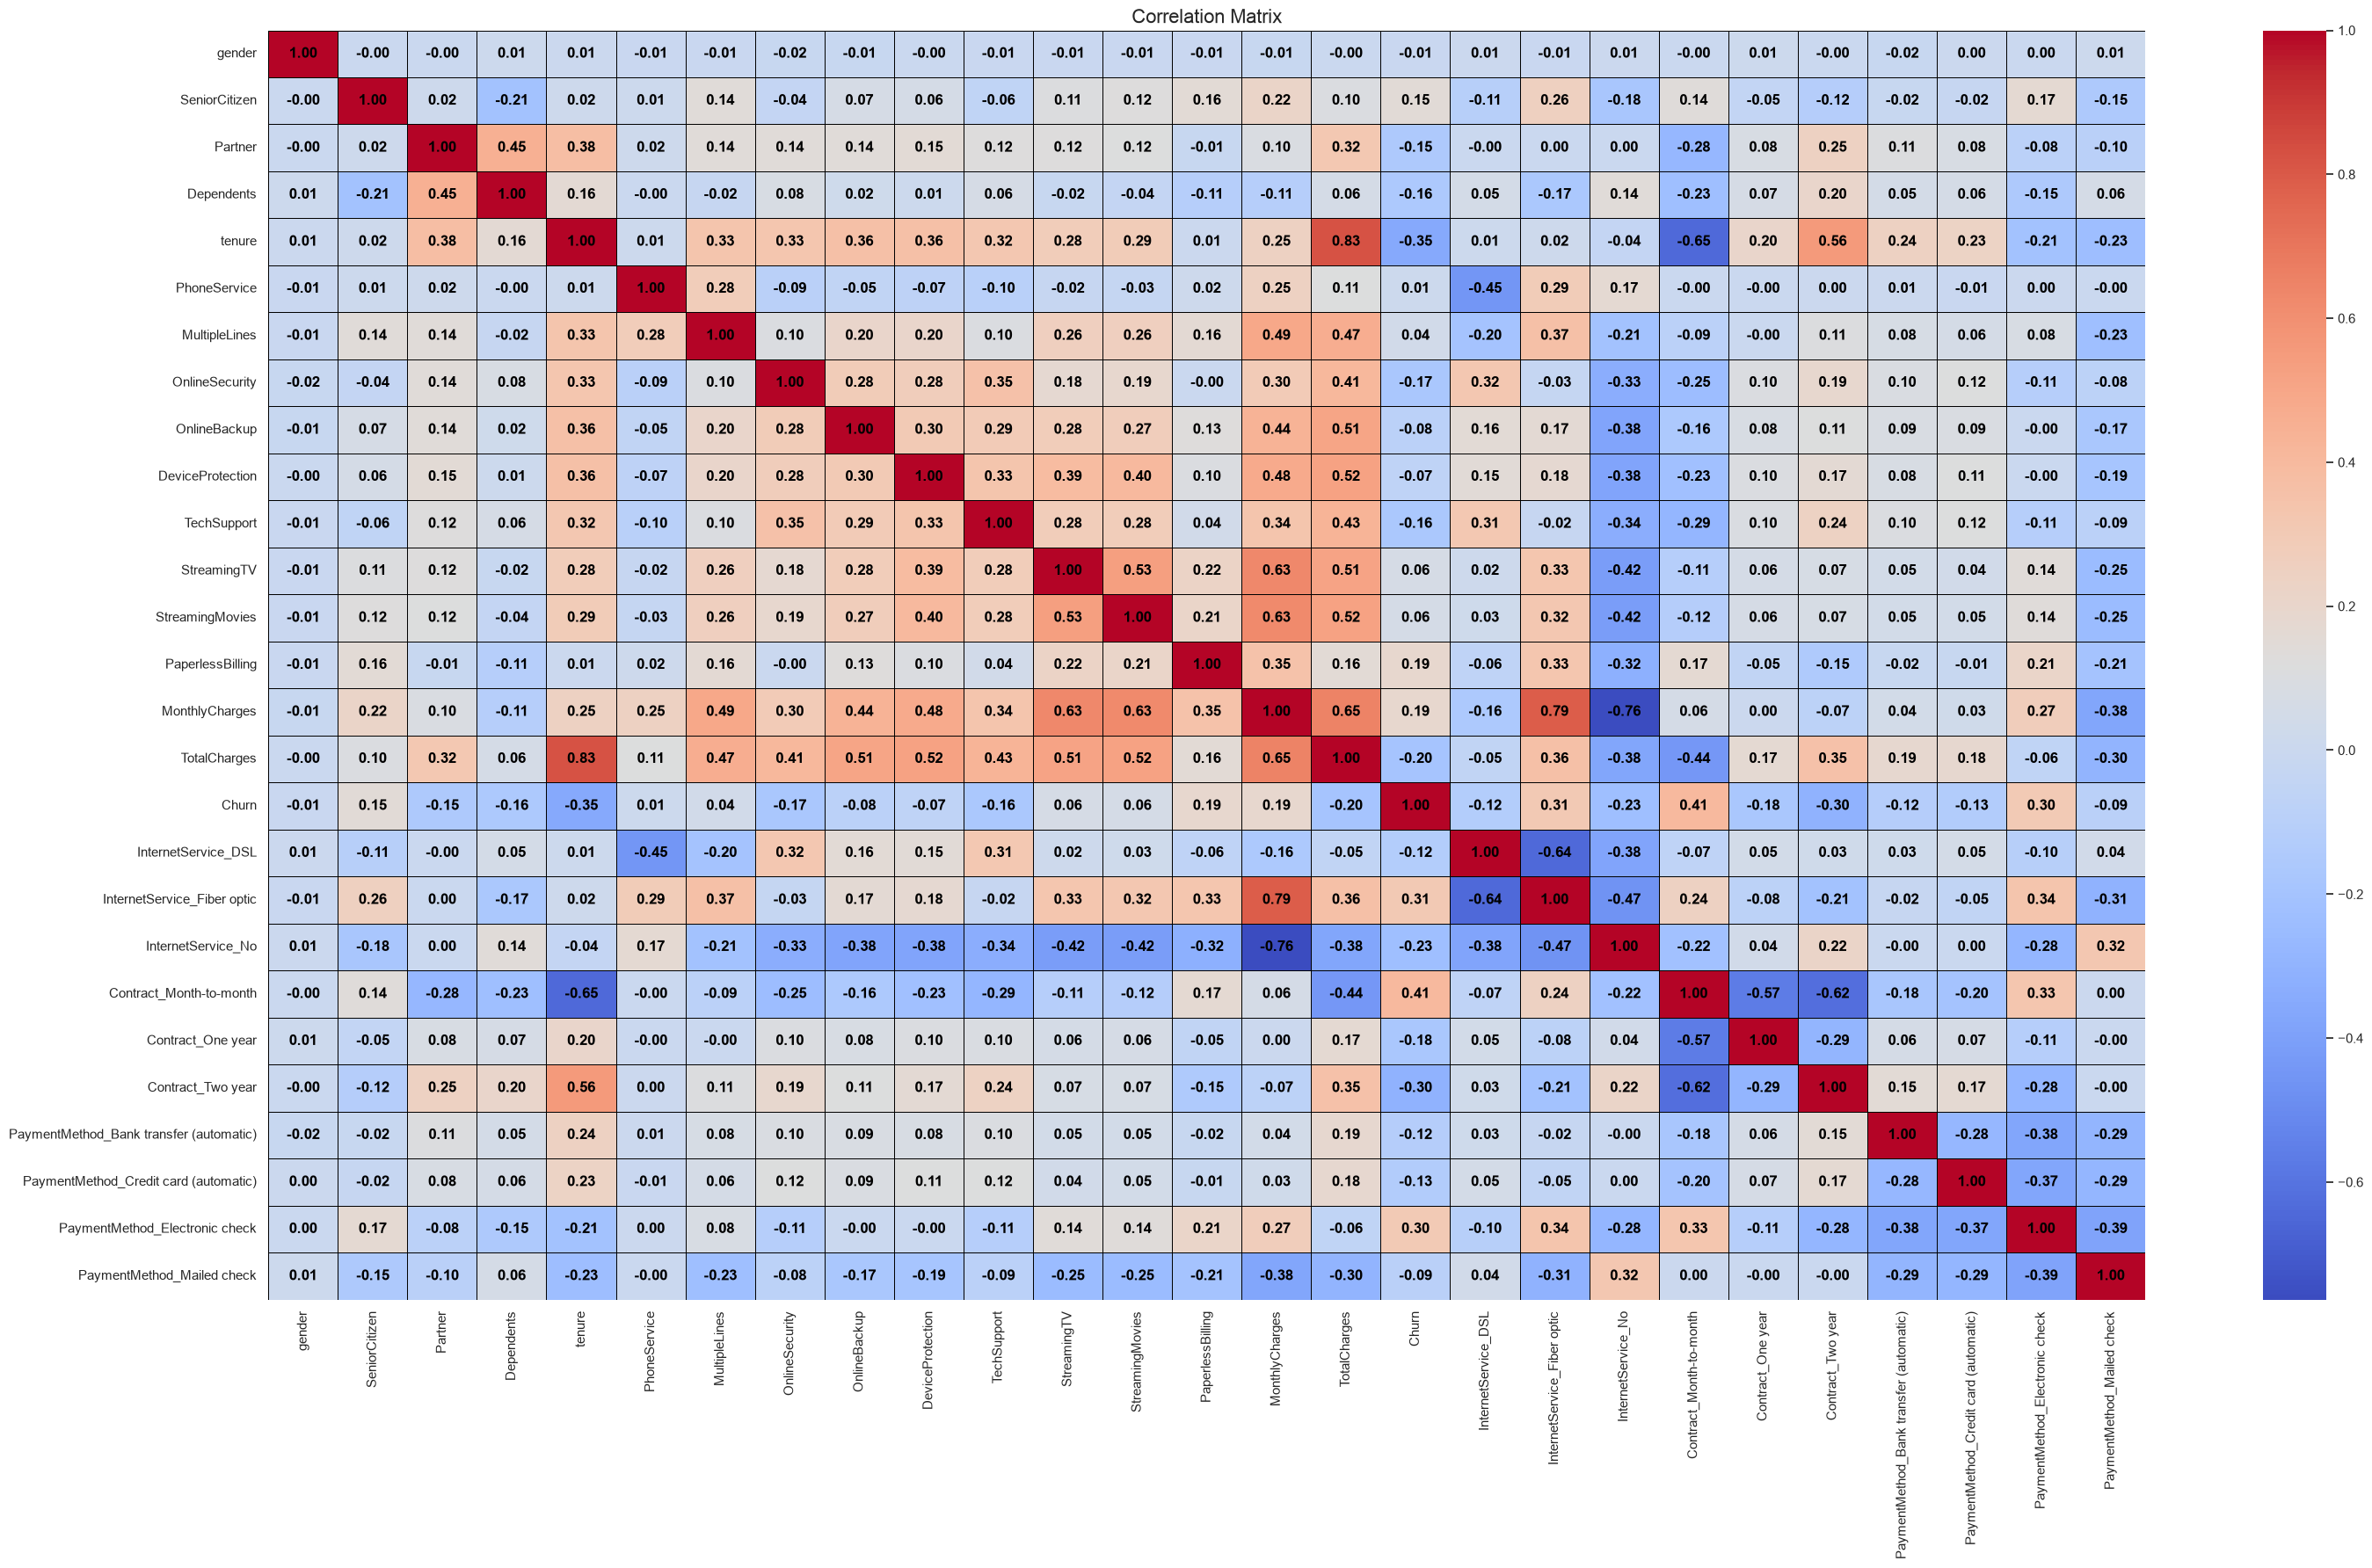

Correlation with churn(ranked):
Churn                                      1.00
Contract_Month-to-month                    0.41
InternetService_Fiber optic                0.31
PaymentMethod_Electronic check             0.30
MonthlyCharges                             0.19
PaperlessBilling                           0.19
SeniorCitizen                              0.15
StreamingTV                                0.06
StreamingMovies                            0.06
MultipleLines                              0.04
PhoneService                               0.01
gender                                    -0.01
DeviceProtection                          -0.07
OnlineBackup                              -0.08
PaymentMethod_Mailed check                -0.09
PaymentMethod_Bank transfer (automatic)   -0.12
InternetService_DSL                       -0.12
PaymentMethod_Credit card (automatic)     -0.13
Partner                                   -0.15
Dependents                                -0.16
TechSupp

In [78]:
# Multivariate Analysis
# Multivariate analysis comparing more than two variables
# How do all our features affect or relate to churn
# Correlation Heatmap

# Drop the temporary columns we creted for plotting

df_corr = df.drop(columns=['Contract_Type', 'Internet_Type', 'PaymentMethod_Type'], errors='ignore')
plt.figure(figsize=(30, 18))
corr_matrix = df_corr.corr()

sns.heatmap(corr_matrix, cmap='coolwarm', annot=True, fmt = '.2f', linewidth=0.5, linecolor = 'black', 
            annot_kws = {'size':12, 'weight':'bold', 'color':'black'}
            )
plt.title('Correlation Matrix', fontsize=16)
plt.tight_layout()
plt.show()

# Print the churn correlation matrix
print('Correlation with churn(ranked):')
print(corr_matrix['Churn'].sort_values(ascending=False).round(2))

In [79]:
# feature Engineering
# vertical split: Feature matrix(X) and Target Variable (y)


# Drop temporary plotting columns and target to get X
X = df.drop(columns=['Churn', 'Contract_Type', 'Internet_Type', 'PaymentMethod_Type'], errors='ignore')

# Target Variable
y = df['Churn']


print(f'Features Shape(X): {X.shape}')
print(f'Target Shape(y): {y.shape}')
print(f'\nFeature columns ({len(X.columns)}):')

for col in X.columns:
    print(f'    -> {col}')


print(f'Target Distribution')
print(y.value_counts())


Features Shape(X): (7043, 26)
Target Shape(y): (7043,)

Feature columns (26):
    -> gender
    -> SeniorCitizen
    -> Partner
    -> Dependents
    -> tenure
    -> PhoneService
    -> MultipleLines
    -> OnlineSecurity
    -> OnlineBackup
    -> DeviceProtection
    -> TechSupport
    -> StreamingTV
    -> StreamingMovies
    -> PaperlessBilling
    -> MonthlyCharges
    -> TotalCharges
    -> InternetService_DSL
    -> InternetService_Fiber optic
    -> InternetService_No
    -> Contract_Month-to-month
    -> Contract_One year
    -> Contract_Two year
    -> PaymentMethod_Bank transfer (automatic)
    -> PaymentMethod_Credit card (automatic)
    -> PaymentMethod_Electronic check
    -> PaymentMethod_Mailed check
Target Distribution
Churn
0    5174
1    1869
Name: count, dtype: int64


In [80]:
# We view X dataframe

X.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='str')

In [81]:
# Horizontal Split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Split Complete')
print(f'\nTraining Set: {X_train.shape[0]} customers (80%)')
print(f'Test Set: {X_test.shape[0]} customers (20%)')

print(f'\nChurn rate in training set: {y_train.mean()*100:.1f}%')
print(f'Churn rate in testing set: {y_test.mean()*100:.1f}%')



Split Complete

Training Set: 5634 customers (80%)
Test Set: 1409 customers (20%)

Churn rate in training set: 26.5%
Churn rate in testing set: 26.5%


In [82]:
# We view first 10 rows of the df Dataframe

df.head(10)



,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_Type,Internet_Type,PaymentMethod_Type
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,True,False,False,True,False,False,False,False,True,False,Month-to-month,No Internet,Electronic check
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,True,False,False,False,True,False,False,False,False,True,One year,No Internet,Mailed check
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,Month-to-month,No Internet,Mailed check
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,True,False,False,False,True,False,True,False,False,False,One year,No Internet,Bank transfer(Auto)
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,False,True,False,True,False,False,False,False,True,False,Month-to-month,No Internet,Electronic check
5,0,0,0,0,8,1,1,0,0,1,0,1,1,1,99.65,820.50,1,False,True,False,True,False,False,False,False,True,False,Month-to-month,No Internet,Electronic check
6,1,0,0,1,22,1,1,0,1,0,0,1,0,1,89.10,1949.40,0,False,True,False,True,False,False,False,True,False,False,Month-to-month,No Internet,Credit card (auto)
7,0,0,0,0,10,0,0,1,0,0,0,0,0,0,29.75,301.90,0,True,False,False,True,False,False,False,False,False,True,Month-to-month,No Internet,Mailed check
8,0,0,1,0,28,1,1,0,0,1,1,1,1,1,104.80,3046.05,1,False,True,False,True,False,False,False,False,True,False,Month-to-month,No Internet,Electronic check
9,1,0,0,1,62,1,0,1,1,0,0,0,0,0,56.15,3487.95,0,True,False,False,False,True,False,True,False,False,False,One year,No Internet,Bank transfer(Auto)


In [83]:
# We view the dataframe statistic summary

df.describe().T


,count,mean,std,min,25%,50%,75%,max
gender,7043.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00
SeniorCitizen,7043.00,0.16,0.37,0.00,0.00,0.00,0.00,1.00
Partner,7043.00,0.48,0.50,0.00,0.00,0.00,1.00,1.00
Dependents,7043.00,0.30,0.46,0.00,0.00,0.00,1.00,1.00
tenure,7043.00,32.37,24.56,0.00,9.00,29.00,55.00,72.00
PhoneService,7043.00,0.90,0.30,0.00,1.00,1.00,1.00,1.00
MultipleLines,7043.00,0.42,0.49,0.00,0.00,0.00,1.00,1.00
OnlineSecurity,7043.00,0.29,0.45,0.00,0.00,0.00,1.00,1.00
OnlineBackup,7043.00,0.34,0.48,0.00,0.00,0.00,1.00,1.00
DeviceProtection,7043.00,0.34,0.48,0.00,0.00,0.00,1.00,1.00


In [84]:
# Scaling Numeric Columns Using StandardScaler
# Z = (value - mean)/standard deviation

scaler = StandardScaler()

# Columns to scale

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Fit ONLY on training set, and transform both (Training and Testing)

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print('Scaling Applied')
print(X_train[numeric_cols].describe().round(2))


Scaling Applied
       tenure  MonthlyCharges  TotalCharges
count 5634.00         5634.00       5634.00
mean    -0.00           -0.00          0.00
std      1.00            1.00          1.00
min     -1.32           -1.54         -1.01
25%     -0.96           -0.97         -0.83
50%     -0.14            0.18         -0.40
75%      0.92            0.83          0.67
max      1.61            1.79          2.80


In [85]:
"""
From our univariate analysis of our target variable (Churn), we have a class imbalance
Stayed  : 5,174 (73.5%)
Churned  : 1,869 (26.5%)

"""

# Fixing class imbalance using SMOTE
# We are applying SMOTE to just our training dataset

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('SMOTE Applied!!')
print(f'\nBefore SMOTE')
print(f'    No Churn: {sum(y_train == 0):,}')
print(f'    Churn:    {sum(y_train == 1):,}')


print(f'\nAfter SMOTE')
print(f'    No Churn: {sum(y_train_sm == 0):,}')
print(f'    Churn:    {sum(y_train_sm == 1):,}')

print(f'\nNew Training set size :  {X_train_sm.shape[0]:,}. customers')


SMOTE Applied!!

Before SMOTE
    No Churn: 4,139
    Churn:    1,495

After SMOTE
    No Churn: 4,139
    Churn:    4,139

New Training set size :  8,278. customers


In [86]:


def model_performance(X_train_sm, y_train_sm, X_test, y_test):
    """
    Evaluate different model performance on our data and their predictions.
    """
    
    models = {

    'Logistic Regression': LogisticRegression(random_state=42, 
                                              max_iter=1000),
    'Random Forest Classifier' : RandomForestClassifier(n_estimators=100, 
                                                        random_state=42),
    'Extreme Gradient Boosting Classifier' : XGBClassifier(n_estimators=100, 
                                     random_state=42, 
                                     eval_metric='logloss', 
                                     verbosity=0)
            }

    # We fit the SMOTE dataset in different models and make predictions.
    for name, model in models.items():
        model.fit(X_train_sm, y_train_sm)
        
        
         # Make the prediction of each model.
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

         # Print the results for evaluation.
        print('=' * 60)
        print(f'  <    {name}    >')
        print('=' * 60)
        print(classification_report(y_test, y_pred, target_names = ['No Churn', 'Churn']))
        print(f'ROC AUC SCORE: {roc_auc_score(y_test, y_proba):.4f}')
        print('')
        


model_performance(X_train_sm, y_train_sm, X_test, y_test)

          

  <    Logistic Regression    >
              precision    recall  f1-score   support

    No Churn       0.89      0.77      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409

ROC AUC SCORE: 0.8355

  <    Random Forest Classifier    >
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409

ROC AUC SCORE: 0.8227

  <    Extreme Gradient Boosting Classifier    >
              precision    recall  f1-score   support

    No Churn       0.87      0.80      0.83      1035
       Churn       0.55      0.66      0.60       374

    accuracy      

In [87]:
# Logistic Regression
# Build and Fit the model
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_sm, y_train_sm)


# Make the prediction of each model.
lr_pred = lr_model.predict(X_test)
lr_proba = lr_model.predict_proba(X_test)[:, 1]

# Evaluate the. model
print('=' * 60)
print(f'  <    LogisticRegression    >')
print('=' * 60)
print(classification_report(y_test, lr_pred, target_names = ['No Churn', 'Churn']))
print(f'ROC AUC SCORE: {roc_auc_score(y_test, lr_proba):.4f}')
print('')
        

  <    LogisticRegression    >
              precision    recall  f1-score   support

    No Churn       0.89      0.77      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409

ROC AUC SCORE: 0.8355



In [88]:
# Random Forest Classifier
# Build and Fit the model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_sm, y_train_sm)


# Make the prediction of each model.
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the. model
print('=' * 60)
print(f'  <    Random Forest Classifier    >')
print('=' * 60)
print(classification_report(y_test, rf_pred, target_names = ['No Churn', 'Churn']))
print(f'ROC AUC SCORE: {roc_auc_score(y_test, rf_proba):.4f}')
print('')
        

  <    Random Forest Classifier    >
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409

ROC AUC SCORE: 0.8227



In [89]:
# Extreme Gradient Boosting Classifier
# Build and Fit the model
xgb_model = XGBClassifier(n_estimators=100,
                         random_state=42, 
                         eval_metric='logloss', 
                         verbosity=0)
xgb_model.fit(X_train_sm, y_train_sm)


# Make the prediction of each model.
xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate the. model
print('=' * 60)
print(f'  <    XGBClassifier    >')
print('=' * 60)
print(classification_report(y_test, xgb_pred, target_names = ['No Churn', 'Churn']))
print(f'ROC AUC SCORE: {roc_auc_score(y_test, xgb_proba):.4f}')
print('')
        

  <    XGBClassifier    >
              precision    recall  f1-score   support

    No Churn       0.87      0.80      0.83      1035
       Churn       0.55      0.66      0.60       374

    accuracy                           0.76      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.76      0.77      1409

ROC AUC SCORE: 0.8120



####                                          **HYPERPARAMTER TUNING: RandomizedSearchCV**

In [90]:
# Hyperparamter Tuning for Logistic Regression
import time
from scipy.stats import randint, uniform, loguniform
from sklearn.metrics import recall_score
from sklearn.model_selection import RandomizedSearchCV,  StratifiedKFold

# Define the Model
lr_model_search = LogisticRegression(random_state=42, max_iter=1000)

# Define the LogisticRegression parameters             
param_dist = [{'solver'       : ['liblinear'],
              'l1_ratio'     : [0, 1],
              'C'            : loguniform(1e-3, 100),
              'class_weight' : [None, 'balanced'],
              'max_iter'     :  [500, 1000],},

{'solver'        : ['lbfgs'],
 'l1_ratio'      : [0],
 'C'             : loguniform(1e-3, 100),
 'class_weight'  : [None, 'balanced'],
 'max_iter'      :  [500, 1000]}]

# Use RandomizedSeacrhCV to fidn best parameters
random_search_lr = RandomizedSearchCV(
            estimator = lr_model_search,
            param_distributions = param_dist,
            scoring = ['recall', 'roc_auc'],
            n_iter = 10,
            refit = 'recall',
            return_train_score = True,
            n_jobs = -1,
            cv = StratifiedKFold(n_splits = 5, shuffle=True, random_state=42),
            random_state=42)

# Fit the model
start = time.time()
random_search_lr.fit(X_train_sm, y_train_sm)
end = time.time()

# Make predictions
y_pred = random_search_lr.predict(X_test) 

# Evaluate the best hyperparameters and score.
print('=' * 65)
print(f'<    Logistic Regression    >')
print('=' * 65)
print(f'Best Score: {random_search_lr.best_score_}')
print(f'Best Recall: {recall_score(y_test, y_pred):.4f}')
print(f'Best Parameters: {random_search_lr.best_params_}')
print(f'Time elapsed(minutes):    {(end - start)/60}')

<    Logistic Regression    >
Best Score: 0.8390968461758641
Best Recall: 0.7246
Best Parameters: {'C': np.float64(1.7965626423790644), 'class_weight': None, 'l1_ratio': 0, 'max_iter': 1000, 'solver': 'lbfgs'}
Time elapsed(minutes):    0.12753647963205975


In [91]:
# Hyperparamter Tuning for RandomForestClassifier
import time
from scipy.stats import randint, uniform, loguniform
from sklearn.metrics import recall_score
from sklearn.model_selection import RandomizedSearchCV,  StratifiedKFold

# Define the Model
rfc_model = RandomForestClassifier(n_estimators = 100, random_state=42 )

# Define the RandomForestClassifier parameters             
param_dist_rfc =  {'n_estimators'      : randint(50, 100),
               'max_depth'         : [None, 10, 20, 30, 40],
               'min_samples_split' : randint(2, 11),
               'min_samples_leaf'  : randint(1, 11),}

# Use RandomizedSeacrhCV to fidn best parameters
random_search_rf = RandomizedSearchCV(
            estimator = rfc_model,
            param_distributions = param_dist_rfc,
            scoring = ['recall', 'roc_auc'],
            n_iter = 10,
            refit = 'recall',
            return_train_score = True,
            n_jobs = -1,
            cv = StratifiedKFold(n_splits = 5, shuffle=True, random_state=42),
            random_state=42)

# Fit the model
start = time.time()
random_search_rf.fit(X_train_sm, y_train_sm)
end = time.time()

# Make predictions
y_pred = random_search_rf.predict(X_test) 

# Evaluate the best hyperparameters and score.
print('=' * 65)
print(f'<    Random Forest Classifier   >')
print('=' * 65)
print(f'Best Score: {random_search_rf.best_score_}')
print(f'Best Recall: {recall_score(y_test, y_pred):.4f}')
print(f'Best Parameters: {random_search_rf.best_params_}')
print(f'Time elapsed(minutes):    {(end - start)/60}')

<    Random Forest Classifier   >
Best Score: 0.8717093388009743
Best Recall: 0.6524
Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 93}
Time elapsed(minutes):    0.14307972987492878


In [92]:
# Hyperparamter Tuning for Extreme Gradient Boosting
import time
from scipy.stats import randint, uniform, loguniform
from sklearn.metrics import recall_score
from sklearn.model_selection import RandomizedSearchCV,  StratifiedKFold

# Define the Model
xgb_model_search = XGBClassifier(objective = 'binary:logistic',
                                        eval_metric = 'logloss',
                                        random_state = 42,
                                        n_jobs = -1)

# Define the Extreme Gradient Boosting parameters             
param_dist_xgb = {'n_estimators'     : randint(100, 1000),
              'max_depth'        : randint(3, 10),
              'learning_rate'    : loguniform(0.01, 0.3),
              'subsample'        : uniform(0.6, 0.4),
              'colsample_bytree' : uniform(0.6, 0.4),
              'min_child_weight' : randint(1, 10),
              'gamma'            : uniform(0, 5),
              'reg_alpha'        : loguniform(1e-3, 10),
              'reg_lambda'       : loguniform(1e-3, 10),}

# Use RandomizedSeacrhCV to fidn best parameters
random_search_xgb = RandomizedSearchCV(
            estimator = xgb_model_search,
            param_distributions = param_dist_xgb,
            scoring = ['recall', 'roc_auc'],
            n_iter = 10,
            refit = 'recall',
            return_train_score = True,
            n_jobs = -1,
            cv = StratifiedKFold(n_splits = 5, shuffle=True, random_state=42),
            random_state=42)

# Fit the model
start = time.time()
random_search_xgb.fit(X_train_sm, y_train_sm)
end = time.time()

# Make predictions
y_pred = random_search_xgb.predict(X_test) 

# Evaluate the best hyperparameters and score.
print('=' * 65)
print(f'<   Extreme Gradient Boosting    >')
print('=' * 65)
print(f'Best Score: {random_search_xgb.best_score_}')
print(f'Best Recall: {recall_score(y_test, y_pred):.4f}')
print(f'Best Parameters: {random_search_xgb.best_params_}')
print(f'Time elapsed(minutes):    {(end - start)/60}')


<   Extreme Gradient Boosting    >
Best Score: 0.8700173492455706
Best Recall: 0.6604
Best Parameters: {'colsample_bytree': np.float64(0.9895022075365837), 'gamma': np.float64(1.1638567021515211), 'learning_rate': np.float64(0.013609328284484965), 'max_depth': 8, 'min_child_weight': 3, 'n_estimators': 975, 'reg_alpha': np.float64(0.11400863701127326), 'reg_lambda': np.float64(0.23423849847112907), 'subsample': np.float64(0.6185801650879991)}
Time elapsed(minutes):    0.20593403577804564


Best Recall for Logistic Regression:  0.72
Best Precision for Logistic Regression:  0.54
Best Accuracy for Logistic Regression:  0.77
Best ROC AUC SCORE for Logistic Regression:  0.75


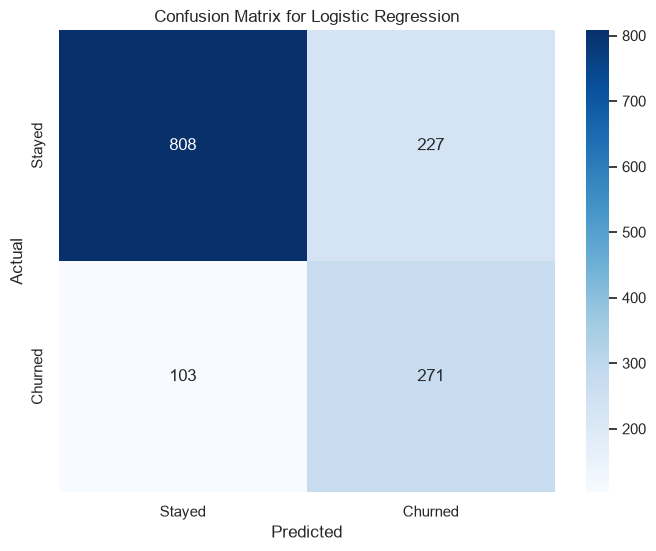

True Negatives (Correctly said stay): 808
False positives (Wrongly said churn): 227
False negatives (Missed churners): 103
True positives (Correctly caught churners): 271

Of 374 actual churners, we caught 72.5%

Best Recall for RandomForestClassifier:  0.65
Best Precision for RandomForestClassifier:  0.56
Best Accuracy for RandomForestClassifier:  0.77
Best ROC AUC SCORE for RandomForestClassifier:  0.73


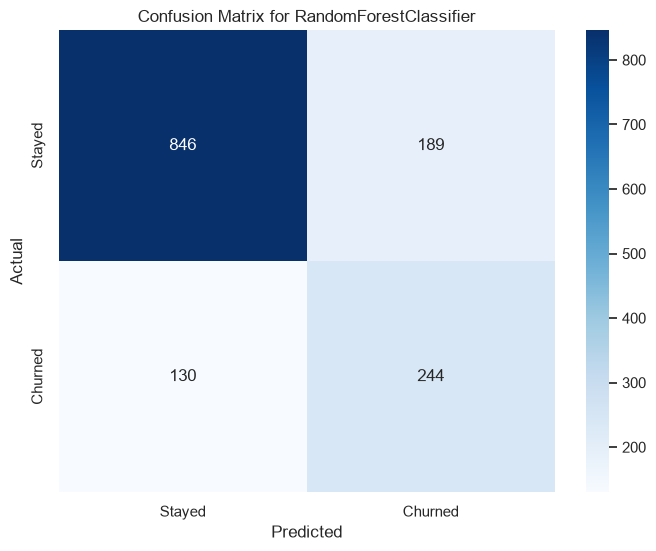

True Negatives (Correctly said stay): 846
False positives (Wrongly said churn): 189
False negatives (Missed churners): 130
True positives (Correctly caught churners): 244

Of 374 actual churners, we caught 65.2%

Best Recall for Extreme Gradient Boosting:  0.66
Best Precision for Extreme Gradient Boosting:  0.56
Best Accuracy for Extreme Gradient Boosting:  0.77
Best ROC AUC SCORE for Extreme Gradient Boosting:  0.73


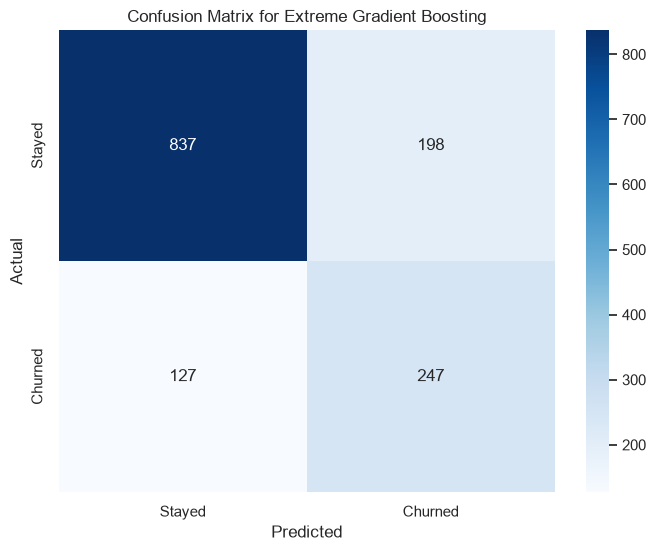

True Negatives (Correctly said stay): 837
False positives (Wrongly said churn): 198
False negatives (Missed churners): 127
True positives (Correctly caught churners): 247

Of 374 actual churners, we caught 66.0%



In [93]:

# Attempt to Increase a threshold to boost recall
from sklearn.metrics import accuracy_score, recall_score, precision_score
models = {
'Logistic Regression'       : random_search_lr,
'RandomForestClassifier'    : random_search_rf,
'Extreme Gradient Boosting' : random_search_xgb
}


for name, model in models.items():
    plt.figure(figsize=(8, 6))
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]


    print(f'Best Recall for {name}:  {recall_score(y_test, y_pred):.2f}')
    print(f'Best Precision for {name}:  {precision_score(y_test, y_pred):.2f}')
    print(f'Best Accuracy for {name}:  {accuracy_score(y_test, y_pred):.2f}')
    print(f'Best ROC AUC SCORE for {name}:  {roc_auc_score(y_test, y_pred):.2f}')

    # Plot the confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    labels = ['Stayed', 'Churned']
    sns.heatmap(cm,
                      annot = True,
                      fmt = 'd',
                      cmap = 'Blues',
                      xticklabels = labels, yticklabels = labels)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix for {name}')
    plt.show()

    # Break down the numbers
    tn, fp, fn, tp = cm.ravel()
    print(f'True Negatives (Correctly said stay): {tn}')
    print(f'False positives (Wrongly said churn): {fp}')
    print(f'False negatives (Missed churners): {fn}')
    print(f'True positives (Correctly caught churners): {tp}')
    print(f'\nOf {tp + fn} actual churners, we caught {tp/(tp + fn) * 100:.1f}%')
    print('')
    print('=' * 60)


Best Recall for Logistic Regression:  0.93
Best Precision for Logistic Regression:  0.42
Best Accuracy for Logistic Regression:  0.64
Best ROC AUC SCORE for Logistic Regression:  0.73


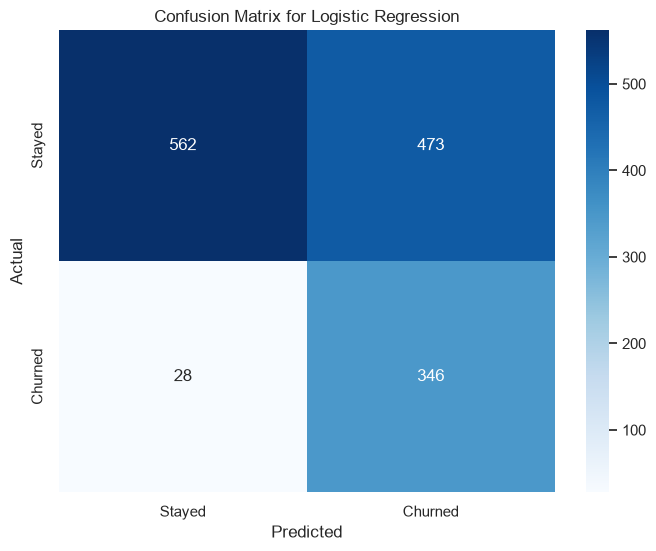

True Negatives (Correctly said stay): 562
False positives (Wrongly said churn): 473
False negatives (Missed churners): 28
True positives (Correctly caught churners): 346

Of 374 actual churners, we caught 92.5%

Best Recall for RandomForestClassifier:  0.91
Best Precision for RandomForestClassifier:  0.42
Best Accuracy for RandomForestClassifier:  0.65
Best ROC AUC SCORE for RandomForestClassifier:  0.73


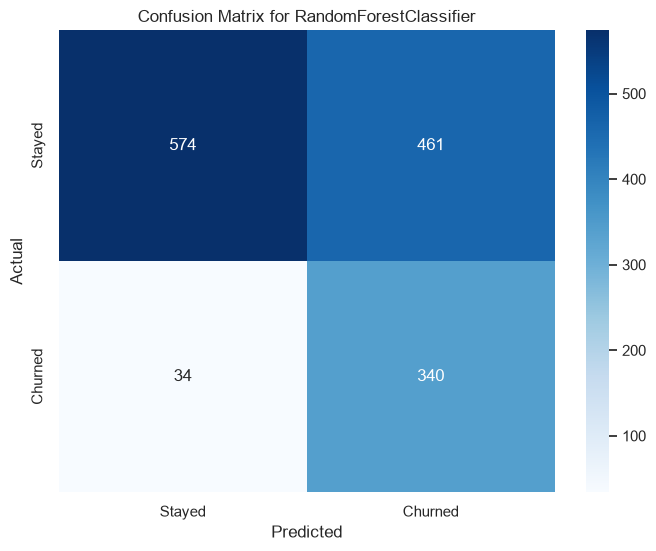

True Negatives (Correctly said stay): 574
False positives (Wrongly said churn): 461
False negatives (Missed churners): 34
True positives (Correctly caught churners): 340

Of 374 actual churners, we caught 90.9%

Best Recall for Extreme Gradient Boosting:  0.86
Best Precision for Extreme Gradient Boosting:  0.45
Best Accuracy for Extreme Gradient Boosting:  0.68
Best ROC AUC SCORE for Extreme Gradient Boosting:  0.74


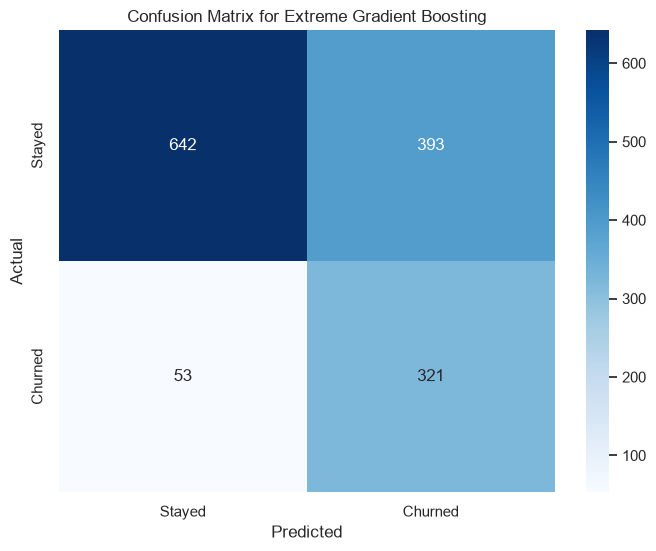

True Negatives (Correctly said stay): 642
False positives (Wrongly said churn): 393
False negatives (Missed churners): 53
True positives (Correctly caught churners): 321

Of 374 actual churners, we caught 85.8%



In [94]:

# Attempt to Increase a threshold to boost recall
from sklearn.metrics import accuracy_score, recall_score, precision_score
models = {
'Logistic Regression'       : random_search_lr,
'RandomForestClassifier'    : random_search_rf,
'Extreme Gradient Boosting' : random_search_xgb
}


for name, model in models.items():
    plt.figure(figsize=(8, 6))
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred_custom =(y_proba > 0.2).astype(int)


    print(f'Best Recall for {name}:  {recall_score(y_test, y_pred_custom):.2f}')
    print(f'Best Precision for {name}:  {precision_score(y_test, y_pred_custom):.2f}')
    print(f'Best Accuracy for {name}:  {accuracy_score(y_test, y_pred_custom):.2f}')
    print(f'Best ROC AUC SCORE for {name}:  {roc_auc_score(y_test, y_pred_custom):.2f}')
    

    # Plot the confusion matrix
    cm = confusion_matrix(y_test, y_pred_custom)
    labels = ['Stayed', 'Churned']
    sns.heatmap(cm,
                      annot = True,
                      fmt = 'd',
                      cmap = 'Blues',
                      xticklabels = labels, yticklabels = labels)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix for {name}')
    plt.show()

    # Break down the numbers
    tn, fp, fn, tp = cm.ravel()
    print(f'True Negatives (Correctly said stay): {tn}')
    print(f'False positives (Wrongly said churn): {fp}')
    print(f'False negatives (Missed churners): {fn}')
    print(f'True positives (Correctly caught churners): {tp}')
    print(f'\nOf {tp + fn} actual churners, we caught {tp/(tp + fn) * 100:.1f}%')
    print('')
    print('=' * 60)
    

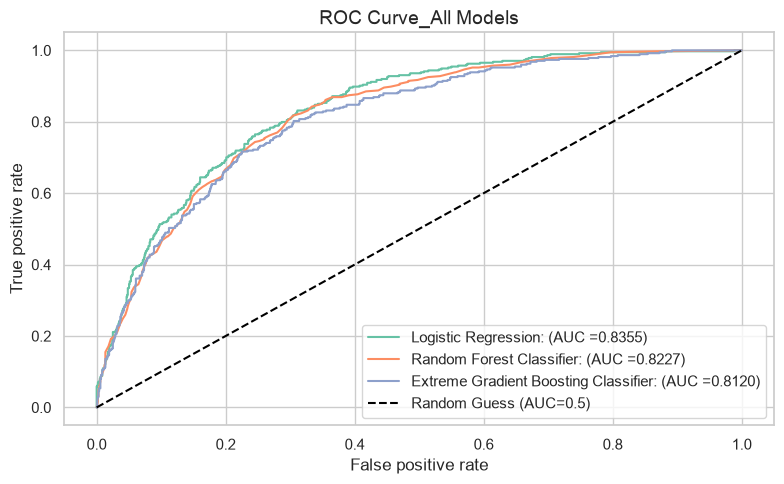

In [95]:
# ROC Curve

plt.figure(figsize=(8,5))
models_proba = {'Logistic Regression' : lr_proba, 
               'Random Forest Classifier' : rf_proba,
               'Extreme Gradient Boosting Classifier' : xgb_proba}
for name, proba in models_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name}: (AUC ={auc:.4f})')

# Add Random guess baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC=0.5)')

# Add plot features
plt.title('ROC Curve_All Models', fontsize=14)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.tight_layout()
plt.show()

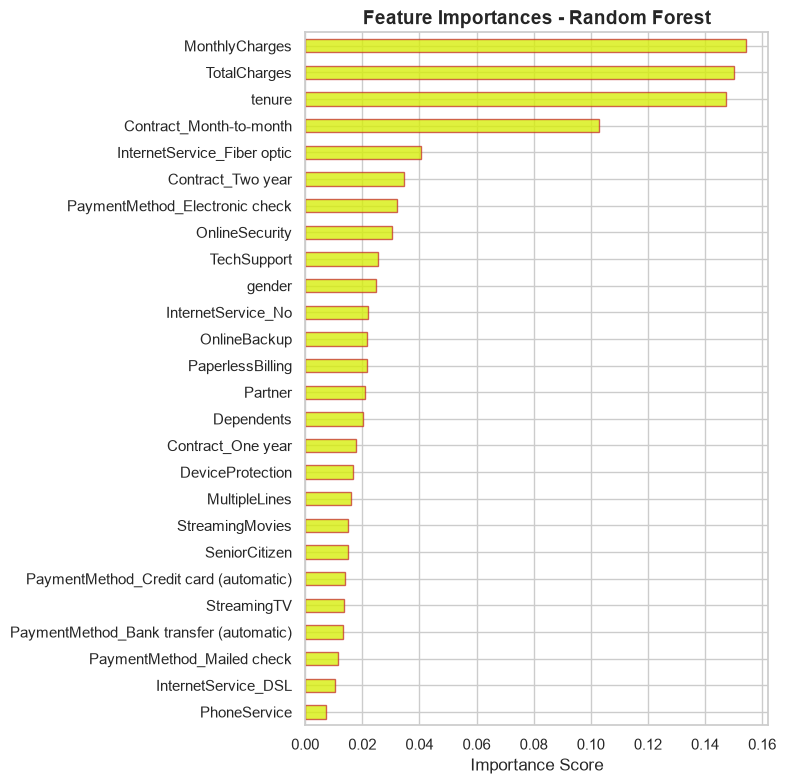

Top 5 Most Important Features:
MonthlyCharges                0.15
TotalCharges                  0.15
tenure                        0.15
Contract_Month-to-month       0.10
InternetService_Fiber optic   0.04
dtype: float64


In [96]:
# Feature Importance - Random Forest

importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=True)

# Plot the feature importance
plt.figure(figsize=(8, 8))
importances.plot(kind = 'barh', color="#d7ee07c7", edgecolor = "#C32626B5")
plt.title('Feature Importances - Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print(f'Top 5 Most Important Features:')
print(importances.sort_values(ascending=False).head(5))

In [97]:
# Save the Mpdel

import joblib

joblib.dump(lr_model, 'churn_model_2.pkl')
joblib.dump(scaler, 'churn_scaler.pkl')
joblib.dump(list(X.columns), 'feature_columns.pkl')

['feature_columns.pkl']

In [98]:
# Hyperparameter Tuning
'''

import time
from scipy.stats import randint, uniform, loguniform
from sklearn.metrics import recall_score
from sklearn.model_selection import RandomizedSearchCV,  StratifiedKFold

models_and_parameters = {

        'Logistic Regression' : {

           'model'        : LogisticRegression(random_state=42, 
                                              max_iter=1000),

           'param_dist'   : [
               
                               {'solver'       : ['liblinear'],
                               'l1_ratio'      : [0, 1],
                               'C'            : loguniform(1e-3, 100),
                               'class_weight' : [None, 'balanced'],
                               'max_iter'     :  [500, 1000],},
                                
                               {'solver'      : ['lbfgs'],
                               'l1_ratio'      : [0],
                               'C'            : loguniform(1e-3, 100),
                               'class_weight' : [None, 'balanced'],
                               'max_iter'     :  [500, 1000]}
           ]},

        'Random Forest Classifier' : {
            'model' : RandomForestClassifier(n_estimators = 100, 
                                             random_state=42 ), 
            'param_dist' : {'n_estimators'      : randint(50, 100),
                            'max_depth'         : [None, 10, 20, 30, 40],
                            'min_samples_split' : randint(2, 11),
                            'min_samples_leaf'  : randint(1, 11),},
                                    },


        'Extreme Gradient Boosting Classifier' : {
                
                'model' : XGBClassifier(objective = 'binary:logistic',
                                        eval_metric = 'logloss',
                                        random_state = 42,
                                        n_jobs = -1),

                'param_dist' : {'n_estimators'     : randint(100, 1000),
                                'max_depth'        : randint(3, 10),
                                'learning_rate'    : loguniform(0.01, 0.3),
                                'subsample'        : uniform(0.6, 0.4),
                                'colsample_bytree' : uniform(0.6, 0.4),
                                'min_child_weight' : randint(1, 10),
                                'gamma'            : uniform(0, 5),
                                'reg_alpha'        : loguniform(1e-3, 10),
                                'reg_lambda'       : loguniform(1e-3, 10),}
        }}

best_models = {}

# Create the RandomizedSearchCV 

for name, classifier in models_and_parameters.items():
        random_search = RandomizedSearchCV(
            estimator = classifier['model'],
            param_distributions = classifier['param_dist'],
            scoring = ['recall', 'roc_auc'],
            n_iter = 10,
            refit = 'recall',
            return_train_score = True,
            n_jobs = -1,
            cv = StratifiedKFold(n_splits = 5, shuffle=True, random_state=42),
            random_state=42)
        
        # Fit the model
        start = time.time()
        random_search.fit(X_train_sm, y_train_sm)
        end = time.time()

        
        best_model = random_search.best_estimator_
        y_pred = best_model.predict(X_test)

        best_models[name] = {'estimator' : best_model, 
                             'recall' : recall_score(y_test, y_pred)}

        # Evaluate the best hyperparameters and score.
        print('=' * 65)
        print(f'<    {name}    >')
        print('=' * 65)
        print(f'Best Model: {best_models}')
        print(f'Best Score: {random_search.best_score_}')
        print(f'Best Recall: {best_models[name]['recall']}')
        print(f'Best Parameters: {random_search.best_params_}')
        print(f'Time elapsed(minutes):    {(end - start)/60}')

        '''

"\n\nimport time\nfrom scipy.stats import randint, uniform, loguniform\nfrom sklearn.metrics import recall_score\nfrom sklearn.model_selection import RandomizedSearchCV,  StratifiedKFold\n\nmodels_and_parameters = {\n\n        'Logistic Regression' : {\n\n           'model'        : LogisticRegression(random_state=42, \n                                              max_iter=1000),\n\n           'param_dist'   : [\n\n                               {'solver'       : ['liblinear'],\n                               'l1_ratio'      : [0, 1],\n                               'C'            : loguniform(1e-3, 100),\n                               'class_weight' : [None, 'balanced'],\n                               'max_iter'     :  [500, 1000],},\n\n                               {'solver'      : ['lbfgs'],\n                               'l1_ratio'      : [0],\n                               'C'            : loguniform(1e-3, 100),\n                               'class_weight' : [None, 'balanc